# Clustering

## Setup and Loading Data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances_chunked, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder


In [2]:
proj_root = Path.cwd()
if proj_root.name == "src":
    proj_root = proj_root.parent
data_dir = proj_root / "data"

In [3]:

cluster_train = pd.read_csv(data_dir/"clustering_train.csv")
cluster_test = pd.read_csv(data_dir / "clustering_test.csv")
cluster_reference = pd.read_csv(data_dir / "clustering_reference.csv")

print("Training shape: ", cluster_train.shape)
print("Test shape: ",cluster_test.shape)
print("Reference shape", cluster_reference.shape)

Training shape:  (100000, 27)
Test shape:  (50000, 27)
Reference shape (100000, 3)


## Preparing Clustering Features

### Selecting Features

In [4]:
# Dropping IDs and month
excluded_cols = ["ID", "Customer_ID", "Name", "SSN", "Month"]
x_cluster = cluster_train.drop(columns=excluded_cols)
x_cluster_test = cluster_test.drop(columns=excluded_cols)

print("Training shape: ", x_cluster.shape)
print("Test shape: ", x_cluster_test.shape)

Training shape:  (100000, 22)
Test shape:  (50000, 22)


Using all features present for the initial k=3 baseline except identifiers and excluding month so clustering is focused on customer characteristics rather than observation month leeching in.

Credit_Score is kept separate.

Annual imcome and monthly salary may provide overlapping information as learned in the EDA notebook. Initially will use both but will try removal later.

### Encoding Categorical Features

Before doing a blanket dummies one hot encoding, 'Type_of_Loan' needs to be handled as there are thousands of different unique strings. The string seems to represent the types of loans present for the person. To handle these  I'll split the string by commas and one hot encode for each of the types split off.

In [5]:
cluster_train["Type_of_Loan"].head()

0    Auto Loan, Credit-Builder Loan, Personal Loan,...
1    Auto Loan, Credit-Builder Loan, Personal Loan,...
2    Auto Loan, Credit-Builder Loan, Personal Loan,...
3    Auto Loan, Credit-Builder Loan, Personal Loan,...
4    Auto Loan, Credit-Builder Loan, Personal Loan,...
Name: Type_of_Loan, dtype: str

In [6]:
# Break into pieces then One hot encode the loan type strings

def encode_loans(values):
    return (
        values.str.replace("and ", "", regex=False) # Get rid of ands
        .str.replace(r"\s*,\s*", "|", regex=True)   # Replace commas with '|'
        .str.get_dummies(sep="|")                   # Dummies separated on '|'
        .add_prefix("Loan_")
    )
    
train_loans = encode_loans(x_cluster["Type_of_Loan"])
# Match test to same cols nd order as train
test_loans = encode_loans(x_cluster_test["Type_of_Loan"]).reindex(
    columns=train_loans.columns, fill_value=0
)

# replace old text with dummies
x_cluster = x_cluster.drop(columns="Type_of_Loan").join(train_loans)
x_cluster_test = x_cluster_test.drop(columns="Type_of_Loan").join(test_loans)

print(train_loans.columns.tolist())

['Loan_Auto Loan', 'Loan_Credit-Builder Loan', 'Loan_Debt Consolidation Loan', 'Loan_Home Equity Loan', 'Loan_Mortgage Loan', 'Loan_No loans', 'Loan_Not Specified', 'Loan_Payday Loan', 'Loan_Personal Loan', 'Loan_Student Loan', 'Loan_Unknown']


In [7]:
# Encoding rest of categorical cols

category_cols = x_cluster.select_dtypes(include=["object", "string", "category"]).columns

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Learning categories from train only
train_categories = encoder.fit_transform(x_cluster[category_cols])
test_categories = encoder.transform(x_cluster_test[category_cols])

# Give readable names, preserve row idx
encoded_cols = encoder.get_feature_names_out(category_cols)

train_categories = pd.DataFrame(train_categories, columns=encoded_cols, index=x_cluster.index)
test_categories = pd.DataFrame(test_categories, columns=encoded_cols, index=x_cluster_test.index)

# Replace with encoded
x_cluster = x_cluster.drop(columns=category_cols).join(train_categories)
x_cluster_test = x_cluster_test.drop(columns=category_cols).join(test_categories)

# Check all features are numeric now
print("Non numeric columns: ",x_cluster.select_dtypes(exclude="number").columns.tolist())
print("Train: ", x_cluster.shape)
print("Test: ", x_cluster_test.shape)

Non numeric columns:  []
Train:  (100000, 58)
Test:  (50000, 58)


### Scaling Features

In [8]:
# Scaling using MinMax scaler, wont touch enoded values

scaler = MinMaxScaler()

# Learn scale from train, transform both
x_cluster_scaled = scaler.fit_transform(x_cluster)
x_cluster_test_scaled = scaler.transform(x_cluster_test)

print("Scaled Train: ", x_cluster_scaled.shape)
print("Scaled Test: ", x_cluster_test_scaled.shape)

Scaled Train:  (100000, 58)
Scaled Test:  (50000, 58)


## K-Means

### Baseline: K = 3

In [9]:
kmeans_baseline = KMeans(n_clusters=3, random_state=24, n_init=10)
baseline_labels = kmeans_baseline.fit_predict(x_cluster_scaled)

print("Cluster Sizes:")
print(pd.Series(baseline_labels).value_counts().sort_index())
print("Inertia: ", kmeans_baseline.inertia_) # Sq distance to assigned cluster center

Cluster Sizes:
0    30818
1    39928
2    29254
Name: count, dtype: int64
Inertia:  453740.35887794336


### Choosing K

#### Elbow Method

K=2: inertia=482,712.18
K=3: inertia=453,740.36
K=4: inertia=437,193.55
K=5: inertia=423,294.81
K=6: inertia=412,964.68
K=7: inertia=407,979.72
K=8: inertia=403,306.17


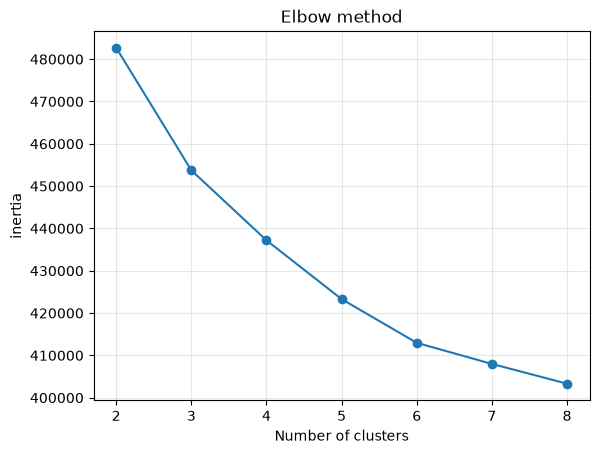

In [10]:
k_values = range(2,9)
kmeans_models = {3: kmeans_baseline}
inertias = []

for k in k_values:
    if k!=3:
        kmeans_models[k] = KMeans(
            n_clusters=k, random_state=24, n_init=10
        ).fit(x_cluster_scaled)
        
    inertias.append(kmeans_models[k].inertia_)
    print(f"K={k}: inertia={inertias[-1]:,.2f}")
    
# Plot elbow curve
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("inertia")
plt.title("Elbow method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

Seems to be no clear elbow, largest inertial drop is from k=2 to k=3. This plot alone doesn't give a decent specific choice of k, will compare silhouette scores before deciding on final k.

#### Silhouette Scores

K=2: silhouette=0.1130
K=3: silhouette=0.1015
K=4: silhouette=0.1093
K=5: silhouette=0.0937
K=6: silhouette=0.0925
K=7: silhouette=0.0787
K=8: silhouette=0.0626


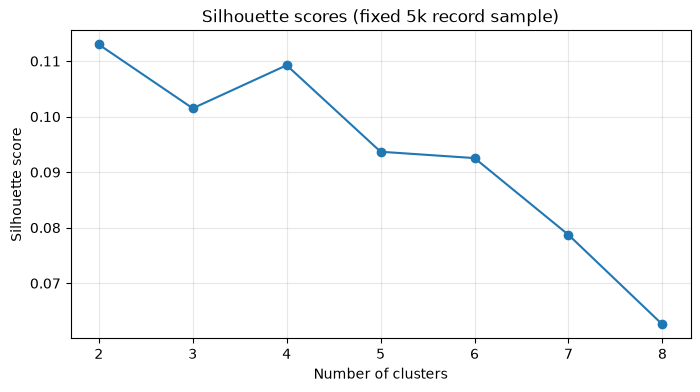

In [11]:
# Create reproducible sample of 5k rows for each test, testing on all would be too slow.
# Gives good enough results.
rng = np.random.default_rng(24)
sample_indices = rng.choice(len(x_cluster_scaled), size = 5000, replace=False)
sample_data = x_cluster_scaled[sample_indices]

silhouette_scores = []
for k in k_values:
    sample_labels = kmeans_models[k].labels_[sample_indices]
    score = silhouette_score(sample_data, sample_labels)
    silhouette_scores.append(score)
    print(f"K={k}: silhouette={score:.4f}")
    
plt.figure(figsize=(8,4))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette scores (fixed 5k record sample)")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

K=2 had the highest silhouette score at 0.1130, with k=4 close behind at 0.1093. All scores were low, suggesting that the clusters are not well separated with the current features and preprocessing.

The elbow plot didn't show a clear choice. I will use k=4 instead of k=2 to explore more detailed customer groups while keeping the silhouette score close to k=2. A deeper look later on will show wether the extra groups are actually useful.

#### Selected K-Means Model

In [12]:
selected_k = 4
selected_kmeans = kmeans_models[selected_k]
selected_labels = selected_kmeans.labels_

### Visualizing K-Means Clusters

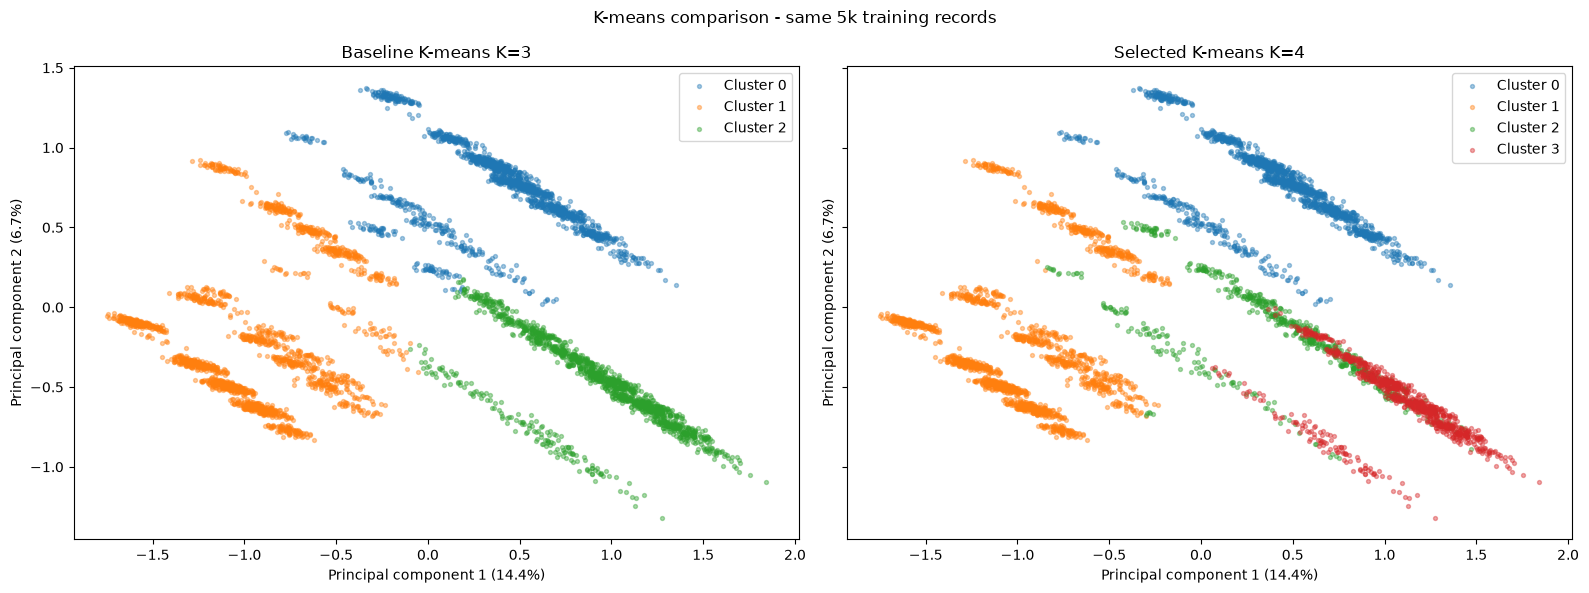

In [13]:
# PCA down to 2d
pca = PCA(n_components=2, random_state=24)
train_pca = pca.fit_transform(x_cluster_scaled)

# Plot fixed sample
rng = np.random.default_rng(24)
plot_indices = rng.choice(len(train_pca), size=5000, replace=False)

fig, axes = plt.subplots(1, 2, figsize = (16,6), sharex=True, sharey=True)
variance = pca.explained_variance_ratio_ * 100

results = [
    (3, kmeans_baseline.labels_, "Baseline"),
    (selected_k, selected_labels, "Selected")
]

for ax, (k, labels, name) in zip(axes, results):
    for cluster in range(k):
        indices = plot_indices[labels[plot_indices] == cluster]
        ax.scatter(
            train_pca[indices, 0],
            train_pca[indices, 1],
            s=8,
            alpha=0.4,
            label=f"Cluster {cluster}"
        )
        
    ax.set_title(f"{name} K-means K={k}")
    ax.set_xlabel(f"Principal component 1 ({variance[0]:.1f}%)")
    ax.set_ylabel(f"Principal component 2 ({variance[1]:.1f}%)")
    ax.legend()
    
plt.suptitle("K-means comparison - same 5k training records")
plt.tight_layout()
plt.show()

The PCA plot shows some separation, especially for cluster 0 and 1. Clusters 2 and 3 have more overlap in this view.

The two comnponents only capture around 20% of the variation, so this plot does not show the full multi-dimensional structure. The low silhouette score suggests that these arent very clearly separated.

## Agglomerative Clustering

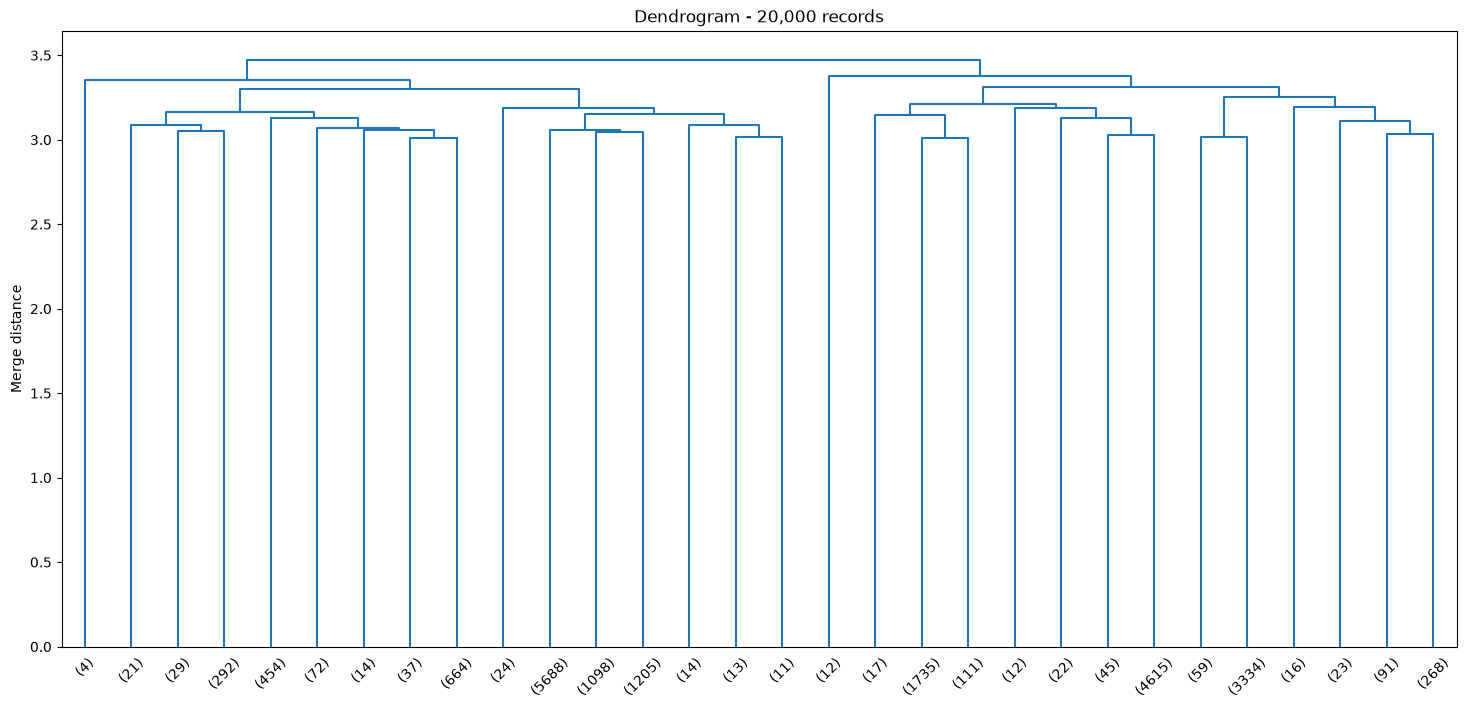

In [14]:
# Inspecting dendrogram to decide how many clusters is best

# Using fixed 20k record sample, agglomerative ends up taking massive space with 100k
sample_size = 20000
rng = np.random.default_rng(24)
sample_indices = rng.choice(len(x_cluster_scaled), sample_size, replace=False)
sample_data = x_cluster_scaled[sample_indices]

average_linkage = linkage(sample_data, method="average", metric="euclidean")

# Showing first 30 branches
plt.figure(figsize=(18,8))
dendrogram(average_linkage, truncate_mode="lastp", p=30)
plt.title(f"Dendrogram - {len(sample_data):,} records")
plt.ylabel("Merge distance")
plt.show()

The dendrogram doesn't show a clear gap suggesting one cluster count over another. Most of the displayed merges occur at similar distances. I will compare a few k values using silhouette and cluster sizes for choosing k.

In [15]:
# Scoring range of ks

agg_labels_by_k = {}
agg_results = []

for k in range(2, 7):
    # Cut existing heirarchy
    labels = cut_tree(average_linkage, n_clusters=k).ravel()
    agg_labels_by_k[k] = labels
    
    # calculate separation and cluster size
    score = silhouette_score(sample_data, labels)
    sizes = pd.Series(labels).value_counts()
    
    agg_results.append({
        "K": k,
        "silhouette": score,
        "smallest_cluster": sizes.min(),
        "largest_cluster": sizes.max()
    })
    
    print(f"K={k}: silhouette={score:.4f}")
    
agg_results = pd.DataFrame(agg_results)
display(agg_results.round(4))

K=2: silhouette=0.1075
K=3: silhouette=0.0795
K=4: silhouette=0.0534
K=5: silhouette=0.0628
K=6: silhouette=0.0675


,K,silhouette,smallest_cluster,largest_cluster
0,2,0.1075,9640,10360
1,3,0.0795,12,10348
2,4,0.0534,4,10348
3,5,0.0628,4,9636
4,6,0.0675,4,8053


K=2 has the highest silhouette score at 0.1075, with clusters containing 9,640 and 10,360 records, almost evenly split. Higher k values gave lower scores and produced some very small groups.

I will use K=2 for agglomerative. The score is still low so the groups are not strongly separated.

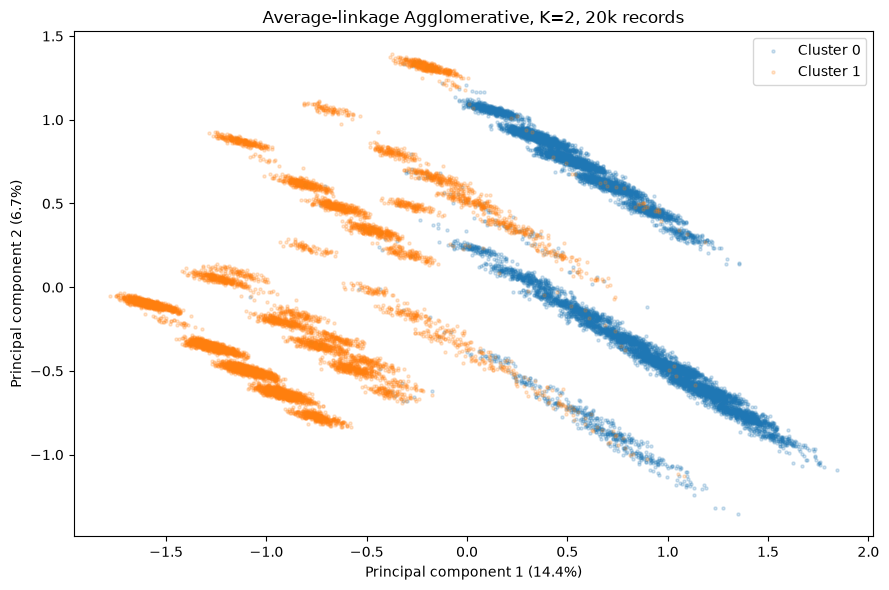

In [16]:
agg_k = 2
agg_labels = agg_labels_by_k[agg_k]

agg_pca = train_pca[sample_indices]

plt.figure(figsize=(9, 6))
for cluster in range(agg_k):
    in_cluster = agg_labels == cluster # Those inside the cluster
    plt.scatter(
        agg_pca[in_cluster, 0],
        agg_pca[in_cluster, 1],
        s=5,
        alpha=0.2,
        label = f"Cluster {cluster}"
    )
    
variance = pca.explained_variance_ratio_ * 100
plt.xlabel(f"Principal component 1 ({variance[0]:.1f}%)")
plt.ylabel(f"Principal component 2 ({variance[1]:.1f}%)")
plt.title("Average-linkage Agglomerative, K=2, 20k records")
plt.legend()
plt.tight_layout()
plt.show()

The two agglomerative clusters mostly occupy different areas along the first PCA component (horizontal), with some overlap. Again the plot only captures 21.1% of variation, but the low silhouette shows that these groups are not strongly separated.

## DBSCAN

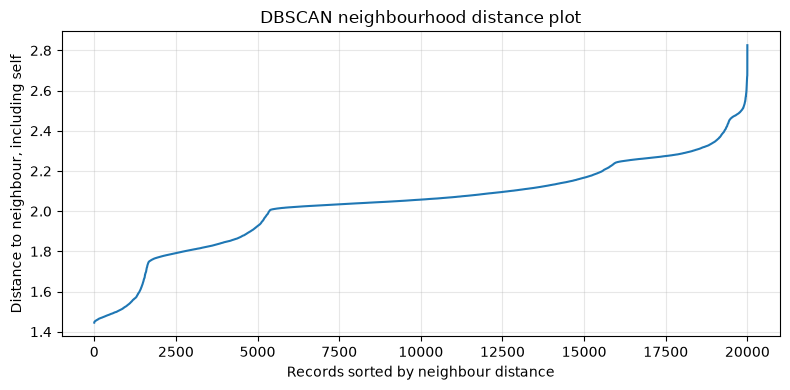

In [17]:
min_samples = sample_data.shape[1] + 1 # Apparently rule of thumb is to set >= dimensions + 1
neighbours = NearestNeighbors(n_neighbors=min_samples, metric="euclidean")
neighbours.fit(sample_data)
distances, _ = neighbours.kneighbors(sample_data) # Using same 20k sample from agglomerative

# Sort distance
neighbour_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8,4))
plt.plot(neighbour_distances)
plt.xlabel("Records sorted by neighbour distance")
plt.ylabel("Distance to neighbour, including self")
plt.title("DBSCAN neighbourhood distance plot")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This plot has a few bends rather than one clear cutoff. Distances rise sharply near the upper end.

I will test eps values of each bend, 1.8, 2.0, 2.2, and 2.4. Because the results weren't great I'll also test some smappes eps values.  
Trying 4, 20, 59 (input dims + 1) and 80 min_samples.

I will compare the number of clusters, their sizes and the percentage of noise records before choosing which is optimal.

In [18]:
eps_vals = [1.4, 1.5, 1.6, 1.7, 1.8, 2.0, 2.2, 2.4]
min_samples_values = [4, 20, 59, 80]
dbscan_results = []

for min_pts in min_samples_values:
    for eps in eps_vals:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_pts,
            metric="euclidean"
        ).fit_predict(sample_data)
        
        # label -1 is the noise, not including in cluster counts
        noise = labels == -1
        sizes = pd.Series(labels[~noise]).value_counts()
        
        dbscan_results.append(
            {
                "eps": eps,
                "min_samples": min_pts,
                "clusters": len(sizes),
                "noise_%": noise.mean() * 100,
                "smallest_cluster": sizes.min() if len(sizes) else 0,
                "largest_cluster": sizes.max() if len(sizes) else 0,
            }
        )
        print(f"Finished eps={eps}, min_samples={min_pts}")
    
display(pd.DataFrame(dbscan_results).round(2))

Finished eps=1.4, min_samples=4
Finished eps=1.5, min_samples=4
Finished eps=1.6, min_samples=4
Finished eps=1.7, min_samples=4
Finished eps=1.8, min_samples=4
Finished eps=2.0, min_samples=4
Finished eps=2.2, min_samples=4
Finished eps=2.4, min_samples=4
Finished eps=1.4, min_samples=20
Finished eps=1.5, min_samples=20
Finished eps=1.6, min_samples=20
Finished eps=1.7, min_samples=20
Finished eps=1.8, min_samples=20
Finished eps=2.0, min_samples=20
Finished eps=2.2, min_samples=20
Finished eps=2.4, min_samples=20
Finished eps=1.4, min_samples=59
Finished eps=1.5, min_samples=59
Finished eps=1.6, min_samples=59
Finished eps=1.7, min_samples=59
Finished eps=1.8, min_samples=59
Finished eps=2.0, min_samples=59
Finished eps=2.2, min_samples=59
Finished eps=2.4, min_samples=59
Finished eps=1.4, min_samples=80
Finished eps=1.5, min_samples=80
Finished eps=1.6, min_samples=80
Finished eps=1.7, min_samples=80
Finished eps=1.8, min_samples=80
Finished eps=2.0, min_samples=80
Finished eps=2.2, 

,eps,min_samples,clusters,noise_%,smallest_cluster,largest_cluster
0,1.4,4,786,68.82,2,61
1,1.5,4,138,25.26,2,14271
2,1.6,4,36,13.30,3,17197
3,1.7,4,35,10.22,2,17817
4,1.8,4,5,3.36,2,19312
5,2.0,4,2,0.58,5,19878
6,2.2,4,1,0.00,20000,20000
7,2.4,4,1,0.00,20000,20000
8,1.4,20,0,100.00,0,0
9,1.5,20,3,70.48,13,5873


Across all of the settings DBSCAN mostly produced noise, many tiny groups or one large cluster. None gave very useful customer segments.  
With the current features and scaling, DBSCAN seems less suitable than the other methods for this dataset.

I will be keeping eps=1.8 and min_samples=4 for the comparison.

In [19]:
dbscan_model = DBSCAN(eps=1.8, min_samples=4, metric="euclidean")
dbscan_labels = dbscan_model.fit_predict(sample_data)
print(pd.Series(dbscan_labels).value_counts().sort_index())

-1      673
 0    19312
 1        4
 2        5
 3        2
 4        4
Name: count, dtype: int64


## Comparing Clustering Methods

In [20]:
# Refitting kmeans on same 20k sample as other models, earlier was fit on all 100k
comparison_kmeans = KMeans(
    n_clusters=selected_k,
    random_state=24,
    n_init=10
).fit(sample_data)

model_labels = {
    "K-Means": comparison_kmeans.labels_,
    "Agglomerative": agg_labels,
    "DBSCAN": dbscan_labels
}

In [21]:
# Function for calculating metrics
# DBScAN and agglomerative dont provide inertia, will calculate the
# same within-cluster squared-distance measure for all 3.

def clustering_metrics(data, labels):
    noise = labels == -1
    points = data[~noise]
    groups = labels[~noise]
    cluster_ids = np.unique(groups)
    
    # Calc total sq dist to each cluster mean
    inertia = 0.0
    for cluster in cluster_ids:
        members = points[groups == cluster]
        center = members.mean(axis=0)
        inertia += ((members - center) ** 2).sum()
        
    # Dunn needs at least 2 clusters
    dunn = np.nan
    if len(cluster_ids) >= 2:
        smallest_gap = np.inf
        largest_diameter = 0.0
        start = 0
        
        # Calc in chunks
        for distances in pairwise_distances_chunked(
            points, metric="euclidean", working_memory=128
        ):
            chunk_groups = groups[start:start + len(distances)]
            
            # Separate distances within clusters from distances between
            for cluster in np.unique(chunk_groups):
                rows = distances[chunk_groups == cluster]
                same_cluster = groups == cluster
                
                largest_diameter = max(
                    largest_diameter,
                    rows[:, same_cluster].max()
                )
                smallest_gap = min(
                    smallest_gap,
                    rows[:, ~same_cluster].min()
                )
                
            start += len(distances)
            
        if largest_diameter > 0:
            dunn = smallest_gap / largest_diameter
    
    return {
        "clusters": len(cluster_ids),
        "records_scored": len(points),
        "noise_%": noise.mean() * 100,
        "dunn_index": dunn,
        "inertia": inertia,
        "inertia_per_record": inertia / len(points) if len(points) else np.nan
    }

In [22]:
# Comparison
comparison_results = []
for name, labels in model_labels.items():
    print(f"Calculating metrics for {name}...")
    result = clustering_metrics(sample_data, labels)
    result["method"] = name
    comparison_results.append(result)
    
comparison_table = pd.DataFrame(comparison_results).set_index("method")
display(comparison_table.round({
    "noise_%": 2,
    "dunn_index": 6,
    "inertia": 2,
    "inertia_per_record": 4
}))

Calculating metrics for K-Means...
Calculating metrics for Agglomerative...
Calculating metrics for DBSCAN...


,clusters,records_scored,noise_%,dunn_index,inertia,inertia_per_record
method,,,,,,
K-Means,4,20000,0.00,0.132319,87453.44,4.3727
Agglomerative,2,20000,0.00,0.263693,97174.81,4.8587
DBSCAN,5,19327,3.36,0.309509,104770.96,5.4210


K-means has the lowest inertia, while agglomerative has a higher dunn index.  
DBSCAN has the highest dunn index, but almost all of of the clustered records belonged to one group, with four tiny groups and 3.36% noise. Therefore t does not indicate any useful broad customer segments.

K-Means and agglomerative remain possibilites. Their cluster profiles need to be checked before deciding which gives more useful groups.

In [23]:
# Comparison of customer characteristics within each cluster
# Excluding DBSCAN at this point.

# Features to inspect
profile_cols = [
    "Age",
    "Monthly_Inhand_Salary",
    "Outstanding_Debt",
    "Num_of_Loan",
    "Delay_from_due_date",
    "Credit_Utilization_Ratio",
    "Credit_History_Age"
]

# Same records from sample
profile_data = cluster_train.iloc[sample_indices][profile_cols].copy()

profile_labels = {
    "K-Means": comparison_kmeans.labels_,
    "Agglomerative": agg_labels
}

# Show cluster sizes and avg feature vals for each method
for name, labels in profile_labels.items():
    grouped = profile_data.assign(Cluster=labels).groupby("Cluster")
    
    summary = grouped[profile_cols].mean()
    summary.insert(0, "Records", grouped.size())
    
    print(f"\n{name}: average values by cluster")
    display(summary.round(2))
    


K-Means: average values by cluster


,Records,Age,Monthly_Inhand_Salary,Outstanding_Debt,Num_of_Loan,Delay_from_due_date,Credit_Utilization_Ratio,Credit_History_Age
Cluster,,,,,,,,
0,3725,29.69,2790.40,2994.73,9.85,38.48,31.60,126.68
1,7769,36.59,5056.07,741.56,6.66,11.79,32.91,286.55
2,5931,31.96,3703.47,1142.09,6.79,19.80,32.05,214.18
3,2575,31.18,3439.44,1771.32,8.77,26.31,31.97,186.15



Agglomerative: average values by cluster


,Records,Age,Monthly_Inhand_Salary,Outstanding_Debt,Num_of_Loan,Delay_from_due_date,Credit_Utilization_Ratio,Credit_History_Age
Cluster,,,,,,,,
0,10360,30.71,3255.26,1984.70,8.54,28.25,31.81,170.27
1,9640,35.95,4851.89,797.71,6.52,13.22,32.81,278.39


Both methods separate records with higher debt and longer payment delays from those with lower debt and shorter delays.

K-Means provides four groups. Cluster 0 has the highest average debt and longest delays, while cluster 1 has the lowest debt and shortest delays. Clusters 2 and 3 are in between these.

Agglomerative gives a broader two group split with similar differences.

Debt and payment delays show us a clear difference between the groups but this doesn't prove they were the main features driving the separations.

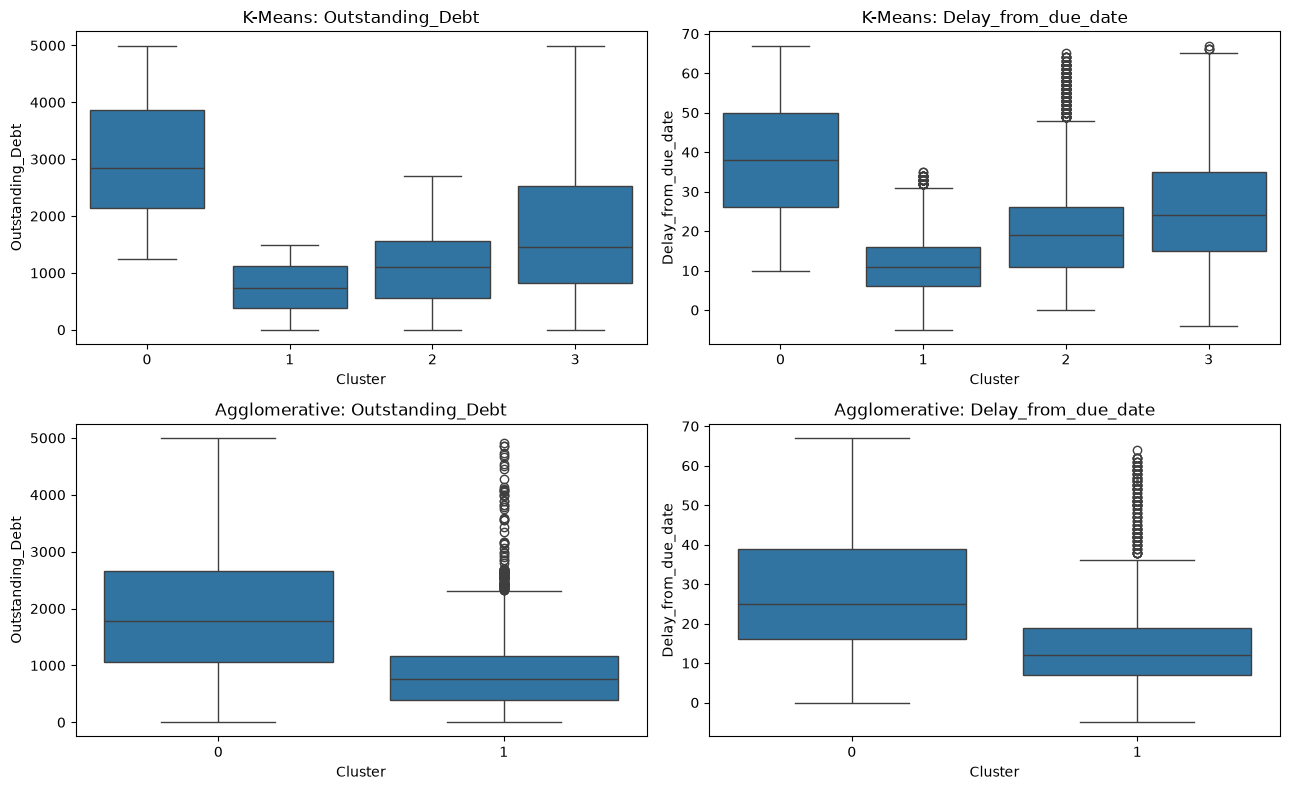

In [24]:
# Taking a closer look at distribution of debt and payment delays within each cluster with boxplot

plot_features = ["Outstanding_Debt", "Delay_from_due_date"]
methods = {
    "K-Means": comparison_kmeans.labels_,
    "Agglomerative": agg_labels
}

# One row per method, one col per feature
fig, axes = plt.subplots(2, 2, figsize=(13,8), sharey="col")
for row, (name, labels) in enumerate(methods.items()):
    plot_data = profile_data.copy()
    plot_data["Cluster"] = labels
    
    for col, feature in enumerate(plot_features):
        sns.boxplot(
            data=plot_data,
            x="Cluster",
            y=feature,
            ax=axes[row,col]
        )
        axes[row,col].set_title(f"{name}: {feature}")
        axes[row, col].set_xlabel("Cluster")

plt.tight_layout()
plt.show()

Taking a closer look, we can see the box plots support the differences seen in the mean values, the extremes arent the only thing separating these.  

K-Means clusters 0 and 1 have noticeably different debt and payment delay distributions. Clusters 2 and 3 overlap more, so those groups are less distinct on these specific features.

Agglomerative gives a broader split between higher debt, longer delay records and lower debt, shorter delay records, with some overlap still.

K-Means gives more detailed groups but neither method separates the customers perfectly.

## Applying Selected Method to Test

I will go with k-means with k=4 for the test set. Its provides more detailed groups than the agglomerative result with 2 clusters. K-means had a lower inertia, although its higher cluster count gives it an advantage here. Agglomerative had a higher dunn index, DBSCAN mostly produced one dominant group with tiny additional groups.

Choosing K-Means is mainly a trade-off rather than a clear win on every metric. The low silhouette scores and overlapping distributions show that there are limitations. Further preprocessing or feature selection would most likely improve this but I'm short on time.

Because I am moving forward with K-means and its fitting was fast enough for me to train on all records in the dataset already, we can use the model that was fitted on all of it rather than just the sample for the test set.

### Labelling the Clusters

Because the test data is unlabelled and has no 'Credit_Score' col, we can label the clusters based on the training data credit scores that I held to the side using the row ID and then carry those labels over for the clusters in the test data.

We can inspect the distribution of credit scores inside the training clusters, the model should distribute the test data that is similar to the same clusters as training.

These are obviously estimates as the model could still assign a random mix of credit scores to a cluster.

In [26]:
# Looking at credit scores in clusters, will label clusters by largest proportion of credit score
train_scores = cluster_train["ID"].map(
    cluster_reference.set_index("ID")["Credit_SCore"] # I left a typo in the csv
)

# Counting scores
score_counts = pd.crosstab(
    selected_kmeans.labels_,
    train_scores,
    rownames=["Cluster"],
).reindex(columns=["Good", "Standard", "Poor"], fill_value=0)
score_percentages = score_counts.div(score_counts.sum(axis=1), axis=0) * 100

# labelling cluster with most common credit score
cluster_to_score = score_counts.idxmax(axis=1)
summary = score_percentages.copy()
summary["Majority Score"] = cluster_to_score
summary["Purity %"] = score_percentages.max(axis=1)
display(summary.round(2))

ID,Good,Standard,Poor,Majority Score,Purity %
Cluster,,,,,
0,5.26,69.43,25.31,Standard,69.43
1,39.22,47.18,13.60,Standard,47.18
2,6.59,55.81,37.60,Standard,55.81
3,1.52,38.40,60.08,Poor,60.08


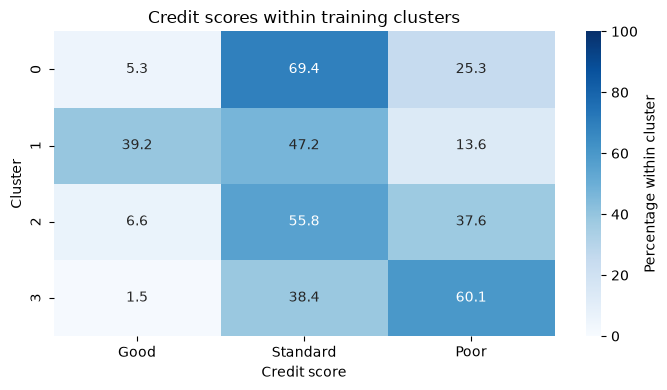

In [33]:
# Credit score mix heatmap
plt.figure(figsize=(7,4))
sns.heatmap(
    score_percentages,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin = 0,
    vmax=100,
    cbar_kws={"label": "Percentage within cluster"}
)
plt.title("Credit scores within training clusters")
plt.xlabel("Credit score")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

I will label clusters 0 and 2 as 'Standard', cluster 1 as 'Good' and cluster 3 as 'Poor.

Clusters 0 and 2 contain mostly standard scores, while cluster 3 contains mostly poor scores. Cluster 1 has the highest proportion of good scores across all clusters at 39.22%, but standard is still it's largest group, for this reason it will take the 'Good' label.

These labels will be carried over for the clusters in the test data to try and classify them. Each cluster contains mixed scores so the estimates may be wrong.

### Labelling Test Clusters

In [27]:
test_clusters = selected_kmeans.predict(x_cluster_test_scaled)

# Keeping each assignment with its original record and customer IDs
test_assignments = cluster_test[["ID", "Customer_ID"]].copy()
test_assignments["Cluster"] = test_clusters

# Counts and percentages for each cluster
test_summary = test_assignments["Cluster"].value_counts().sort_index().to_frame("Records")
test_summary["Percentage"] = test_summary["Records"] / len(test_assignments) * 100

display(test_summary.round(2))

,Records,Percentage
Cluster,,
0,14826,29.65
1,19295,38.59
2,6323,12.65
3,9556,19.11


In [28]:
# Applying manual labels from before
cluster_to_score = {1: "Good", 0: "Standard", 2: "Standard", 3: "Poor"}
test_assignments["Estimated_Credit_Score"] = (test_assignments["Cluster"].map(cluster_to_score))

# Looking at how many test records got each score category
credit_summary = (
    test_assignments["Estimated_Credit_Score"]
    .value_counts()
    .reindex(["Good", "Standard", "Poor"], fill_value=0)
    .to_frame("Records")
)
credit_summary["Percentage"] = credit_summary["Records"] / len(test_assignments) * 100

display(credit_summary.round(2))

,Records,Percentage
Estimated_Credit_Score,,
Good,19295,38.59
Standard,21149,42.30
Poor,9556,19.11


Using the manual cluster mapping, 38.59% of test records were labelled good, 42.30% standard and 19.11% poor.

These are obviously estimates but we can check a few ways to see if the labels seem good, I will look into the financials of the good cluster.

A decent assumption should be, people with high incomes and low debt payment times should have a good credit score. While not exact this will give us some insights into how reasonable the manual mapping was.

In [29]:
# Comparing financials across the test clusters
test_profiles = cluster_test[
    ["Monthly_Inhand_Salary", "Outstanding_Debt", "Delay_from_due_date"]
].copy()

# Attach the manual labels
test_profiles["Estimated_Credit_Score"] = test_assignments["Estimated_Credit_Score"]

display(
    test_profiles.groupby("Estimated_Credit_Score")
    .median().reindex(["Good", "Standard", "Poor"]).round(2)
)

,Monthly_Inhand_Salary,Outstanding_Debt,Delay_from_due_date
Estimated_Credit_Score,,,
Good,3232.73,725.09,11.0
Standard,3095.90,1240.11,20.0
Poor,2849.09,2845.28,38.0


Wow my assumption was kind of correct.

The estimated good group has the lowest median debt (725.09) and shortest median payment delay (11 days). The poor group has the highest debt (2845.28) and longest delay (38 days), with standard falling in between.

Median salary is also the highest for good and lowest for poor.

These patterns support the reasoning behind the manual labels, but don't confirm the credit scores are correct. These are median values as well, the individual records my differ by a lot. 